In [18]:
"""
Base environment for multiple optimal stopping problems.
Compatible with Gymnasium interface for future extensibility.
"""
from typing import Optional, Tuple, Dict, Any, Callable
import numpy as np
from abc import ABC, abstractmethod
from tqdm import tqdm 
import matplotlib.pyplot as plt

class BaseStoppingEnv(ABC):
    """Base class for optimal stopping environments (Standalone)."""
    
    def __init__(
        self,
        n_states: int,
        max_time: int,
        max_stops: int,
        transition_model: str = 'random_walk',
        transition_params: Optional[Dict[str, Any]] = None,
        seed: Optional[int] = None
    ):
        self.n_states = n_states
        self.max_time = max_time
        self.max_stops = max_stops
        self.transition_model = transition_model
        self.transition_params = transition_params or {}
        
        self.np_random = np.random.default_rng(seed)
        self._init_transition_matrix()
        
    def _init_transition_matrix(self):
        if self.transition_model == 'brownian':
            self.P = self._create_brownian_transition()
        elif self.transition_model == 'random_walk':
            self.P = self._create_random_walk_transition()
        else:
            self.P = np.eye(self.n_states)
            
    def _create_brownian_transition(self) -> np.ndarray:
        mu = self.transition_params.get('mu', 0.0)
        sigma = self.transition_params.get('sigma', 1.0)
        
        P = np.zeros((self.n_states, self.n_states))
        
        for i in range(self.n_states):
            for j in range(self.n_states):
                # Simple discrete approximation
                diff = j - i
                P[i, j] = np.exp(-0.5 * ((diff - mu) / sigma) ** 2)
            
            # Normalize
            if P[i, :].sum() > 0:
                P[i, :] /= P[i, :].sum()
            else:
                P[i, i] = 1.0
        
        return P

    def _create_random_walk_transition(self) -> np.ndarray:
        return np.eye(self.n_states)
    
    @abstractmethod
    def solve_optimal_policy(self):
        pass

class DoubleSellEnv(BaseStoppingEnv):
    def __init__(
        self,
        n_states: int,
        max_time: int,
        sell_cost: float = 0.2,
        offer_values: Optional[np.ndarray] = None,
        transition_model: str = "random_walk",
        transition_params: Optional[Dict[str, Any]] = None,
        seed: Optional[int] = None,
    ):
        super().__init__(
            n_states=n_states,
            max_time=max_time,
            max_stops=2,
            transition_model=transition_model,
            transition_params=transition_params,
            seed=seed,
        )

        self.sell_cost = sell_cost
        if offer_values is None:
            self.offer_values = np.linspace(0, n_states, n_states)
        else:
            self.offer_values = offer_values

    def solve_optimal_policy(self, verbose: bool = True):
        S, T = self.n_states, self.max_time
        P = self.P
        c = self.sell_cost
        v = self.offer_values

        V = np.zeros((S, T + 1, 3))
        policy = np.zeros((S, T + 1, 3), dtype=int)

        # --- FIX: Smoother Boundary Conditions ---
        
        # t=0: Everything is 0 (Expired)
        V[:, 0, :] = 0.0
        
        # t=1: Last chance to act
        # If z=1 (Last Sell): Value is just the offer v
        V[:, 1, 1] = v
        policy[:, 1, 1] = 1
        
        # If z=2 (Double Sell): 
        # ORIGINAL: V = v - c (Forces you to pay 'first sell' cost) -> KINK
        # FIXED:    V = v     (Collapses to single sell, no extra cost) -> SMOOTH
        V[:, 1, 2] = v 
        policy[:, 1, 2] = 1 # Always sell if it's positive (and here v >= 0)

        # Backward Induction
        for t in range(2, T + 1):
            # z = 1 (Last Sell Left)
            cont_1 = -c + P @ V[:, t - 1, 1]  # paying 'holding/continuation' cost or just standard penalty? 
            # Note: in original code, 'c' was used as sell_cost. 
            # If standard double sell problem, usually holding is free, selling is costly.
            # Assuming 'c' is transaction cost only paid on First Sell in sequential model.
            # But the provided code used it as "continuation penalty" for single sell too?
            # Let's stick to the prompt's implied logic:
            
            # Recalculating based on standard Double Stopping:
            # Stop 1 (Last): Receive v.
            # Stop 2 (First): Receive v - c, move to state with 1 stop left.
            
            # Using prompt's logic for consistency:
            cont_1 = P @ V[:, t - 1, 1] # Simple continuation for last sell
            stop_1 = v
            V[:, t, 1] = np.maximum(cont_1, stop_1)
            policy[:, t, 1] = (stop_1 >= cont_1).astype(int)

            # z = 2 (First Sell Left)
            cont_2 = P @ V[:, t - 1, 2]
            stop_2 = v - c + P @ V[:, t - 1, 1] # Pay cost c, get cash v, get option V_1
            
            V[:, t, 2] = np.maximum(cont_2, stop_2)
            policy[:, t, 2] = (stop_2 >= cont_2).astype(int)

        return V, policy

class visualizer:
    def __init__(self, env, agent, optimal_policy=None):
        self.env = env
        self.agent = agent
        self.optimal_policy = env.solve_optimal_policy()[1] if optimal_policy is None else optimal_policy
    
    def plot_visit_counts(self):
        offer_visit_counts = (self.agent.visit_counts.sum(axis=(1,2)))
        plt.bar(range(len(offer_visit_counts)), offer_visit_counts)
        plt.xlabel('Offer Value Index')
        plt.ylabel('Number of Visits')
        plt.title('State Visit Counts by Offer Value (Sanity check)')
        plt.show()
    
    def plot_episode_rewards(self, rolling_window=100):
        rewards = self.agent.episode_rewards
        # rolling average over 100 episodes
        rewards = np.convolve(rewards, np.ones(rolling_window)/rolling_window, mode='valid')
        plt.plot(rewards)
        plt.xlabel('Episode')
        plt.ylabel('Total Reward')
        plt.title('Episode Rewards over Time')
        plt.show()

    def visualise_Q_table(self):
        Q = self.agent.Q  # shape: (T+1, S, 2, 2)

        # Remove terminal time step
        Q_view = Q[:-1, :, :, :]  # (T, S, z_idx, action)

        vmin = np.min(Q_view)
        vmax = np.max(Q_view)

        T = Q_view.shape[0]
        time_ticks = np.arange(0, T, max(1, T // 5))
        time_labels = time_ticks

        fig, axs = plt.subplots(2, 2, figsize=(12, 10))

        # z = 1 (second stop left)
        axs[0, 0].imshow(Q_view[:, :, 0, 0].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[0, 0].set_title("Q(z=1): Continue")

        axs[0, 1].imshow(Q_view[:, :, 0, 1].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[0, 1].set_title("Q(z=1): Stop")

        # z = 2 (first stop left)
        axs[1, 0].imshow(Q_view[:, :, 1, 0].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[1, 0].set_title("Q(z=2): Continue")

        axs[1, 1].imshow(Q_view[:, :, 1, 1].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[1, 1].set_title("Q(z=2): Stop")

        for ax in axs.flat:
            ax.set_xlabel("Time")
            ax.set_ylabel("State")
            ax.set_xticks(time_ticks)
            ax.set_xticklabels(time_labels)

        plt.tight_layout()
        plt.show()


    def visualise_policy(self):
        """
        Visualize the learned double-sell policy.
        stop=1 means 'sell', stop=0 means 'continue'
        """
        policy = self.agent.get_policy()  # (state, time, stops)

        # Align dimensions
        policy = policy[:, :-1, :]  # remove terminal time
        S, T, _ = policy.shape

        time_ticks = np.arange(0, T, max(1, T // 5))
        time_labels = time_ticks

        fig, axs = plt.subplots(1, 2, figsize=(14, 5))

        # -------- First Sell (z = 2) --------
        first_sell_policy = policy[:, :, 2]

        im1 = axs[0].imshow(
            first_sell_policy,
            cmap="RdYlGn",
            vmin=0,
            vmax=1,
            aspect="auto",
            origin="lower"
        )
        axs[0].set_title("First Sell Policy", fontsize=13, fontweight="bold")
        axs[0].set_xlabel("Time")
        axs[0].set_ylabel("State")
        axs[0].set_xticks(time_ticks)
        axs[0].set_xticklabels(time_labels)

        cbar1 = plt.colorbar(im1, ax=axs[0])
        cbar1.set_ticks([0, 1])
        cbar1.set_ticklabels(["Continue", "Sell"])

        # -------- Second Sell (z = 1) --------
        second_sell_policy = policy[:, :, 1]

        im2 = axs[1].imshow(
            second_sell_policy,
            cmap="RdYlGn",
            vmin=0,
            vmax=1,
            aspect="auto",
            origin="lower"
        )
        axs[1].set_title("Second Sell Policy", fontsize=13, fontweight="bold")
        axs[1].set_xlabel("Time")
        axs[1].set_ylabel("State")
        axs[1].set_xticks(time_ticks)
        axs[1].set_xticklabels(time_labels)

        cbar2 = plt.colorbar(im2, ax=axs[1])
        cbar2.set_ticks([0, 1])
        cbar2.set_ticklabels(["Continue", "Sell"])

        plt.tight_layout()
        plt.show()

        # ---- Statistics ----
        print("\nDouble-Sell Policy Statistics:")
        print(f" First sell rate: {first_sell_policy.mean():.2%}")
        print(f" Second sell rate: {second_sell_policy.mean():.2%}")
        
    def compare_with_optimal(self):
        """
        Compare Q-learning policy with optimal DP policy
        for a double-sell stopping problem.
        """

        if self.optimal_policy is None:
            print("⚠ Optimal policy not provided.")
            return

        # -------- Get policies --------
        q_policy = self.agent.get_policy()        # (S, Tq, 3)
        opt_policy = self.optimal_policy          # (S, To, 3)

        # -------- Explicit time alignment --------
        T = min(q_policy.shape[1], opt_policy.shape[1])

        q_policy_view = q_policy[:, :T, :]
        opt_policy_view = opt_policy[:, :T, :]

        # -------- HARD SAFETY CHECK --------
        if q_policy_view.shape != opt_policy_view.shape:
            raise ValueError(
                f"Policy shape mismatch after alignment:\n"
                f"Q-policy: {q_policy_view.shape}\n"
                f"OPT-policy: {opt_policy_view.shape}"
            )

        # -------- First sell (z = 2) --------
        q_first = q_policy_view[:, :, 2]
        opt_first = opt_policy_view[:, :, 2]

        diff_first_sell = (q_first != opt_first).astype(float)

        # -------- Second sell (z = 1) --------
        q_second = q_policy_view[:, :, 1]
        opt_second = opt_policy_view[:, :, 1]

        diff_second_sell = (q_second != opt_second).astype(float)

        # -------- Plot --------
        fig, axs = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle("Policy Comparison: Q-Learning vs Optimal (Double Sell)", fontsize=16)

        # First sell
        im1 = axs[0, 0].imshow(q_first, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 0].set_title("Q-Learning: First Sell")
        plt.colorbar(im1, ax=axs[0, 0])

        im2 = axs[0, 1].imshow(opt_first, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 1].set_title("Optimal: First Sell")
        plt.colorbar(im2, ax=axs[0, 1])

        im3 = axs[0, 2].imshow(diff_first_sell, cmap="Reds", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 2].set_title(f"Mismatch (First Sell): {diff_first_sell.mean():.1%}")
        plt.colorbar(im3, ax=axs[0, 2])

        # Second sell
        im4 = axs[1, 0].imshow(q_second, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 0].set_title("Q-Learning: Second Sell")
        plt.colorbar(im4, ax=axs[1, 0])

        im5 = axs[1, 1].imshow(opt_second, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 1].set_title("Optimal: Second Sell")
        plt.colorbar(im5, ax=axs[1, 1])

        im6 = axs[1, 2].imshow(diff_second_sell, cmap="Reds", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 2].set_title(f"Mismatch (Second Sell): {diff_second_sell.mean():.1%}")
        plt.colorbar(im6, ax=axs[1, 2])

        plt.tight_layout()
        plt.show()

        # -------- Stats --------
        print("\nPolicy Agreement Statistics (Double Sell)")
        print(f" First sell agreement: {(1 - diff_first_sell.mean()):.2%}")
        print(f" Second sell agreement: {(1 - diff_second_sell.mean()):.2%}")

        total_agreement = 1 - (diff_first_sell.sum() + diff_second_sell.sum()) / (
            diff_first_sell.size + diff_second_sell.size
        )
        print(f" Overall agreement: {total_agreement:.2%}")

    def pipeline(self, compare_optimal=True):
        self.plot_visit_counts()
        self.plot_episode_rewards()
        self.visualise_Q_table()
        self.visualise_policy()
        if compare_optimal and self.optimal_policy is not None:
            self.compare_with_optimal()

    def compare_values(self):
        """
        Heatmap comparison of Optimal Value Function vs LSM Estimated Values.
        """
        # 1. Get Values
        V_opt, _ = self.env.solve_optimal_policy(verbose=False)
        V_lsm = self.agent.get_value_estimate()
        
        # Align shapes (remove terminal step for cleaner plotting if desired, or keep it)
        T = self.env.max_time
        V_opt = V_opt[:, :T, :]
        V_lsm = V_lsm[:, :T, :]
        
        # Calculate Difference
        V_diff = V_opt - V_lsm
        
        # 2. Setup Plot
        fig, axs = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle("Value Function Comparison: Optimal (DP) vs Estimated (LSM)", fontsize=16)
        
        time_ticks = np.arange(0, T, max(1, T // 5))
        
        # --- Helper to plot ---
        def plot_heatmap(ax, data, title, cmap="viridis"):
            im = ax.imshow(data, aspect='auto', origin='lower', cmap=cmap)
            ax.set_title(title)
            ax.set_xlabel("Time")
            ax.set_ylabel("State (Offer)")
            ax.set_xticks(time_ticks)
            plt.colorbar(im, ax=ax)

        # --- Row 1: First Sell (Stop 2) ---
        plot_heatmap(axs[0, 0], V_opt[:, :, 2], "Optimal Value (First Sell)")
        plot_heatmap(axs[0, 1], V_lsm[:, :, 2], "LSM Value (First Sell)")
        plot_heatmap(axs[0, 2], V_diff[:, :, 2], "Difference (Opt - LSM)", cmap="coolwarm")
        
        # --- Row 2: Second Sell (Stop 1) ---
        plot_heatmap(axs[1, 0], V_opt[:, :, 1], "Optimal Value (Last Sell)")
        plot_heatmap(axs[1, 1], V_lsm[:, :, 1], "LSM Value (Last Sell)")
        plot_heatmap(axs[1, 2], V_diff[:, :, 1], "Difference (Opt - LSM)", cmap="coolwarm")

        plt.tight_layout()
        plt.show()
        
        # Print Stats
        mse_2 = np.mean(V_diff[:, :, 2]**2)
        print(f"\nValue Approximation Error (MSE):")
        print(f"  First Sell (Stop 2): {mse_2:.4f}")
        print(f"  Last Sell  (Stop 1): {np.mean(V_diff[:, :, 1]**2):4f}")


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from typing import Optional, Dict, Tuple, List, Any
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from typing import Optional, Dict, Tuple, List, Any

class LSMDoubleSell:
    def __init__(
        self,
        env,
        poly_degree: int = 3,
        basis_mode: str = 'state', # Revert to 'state' to avoid multicollinearity
        seed: Optional[int] = None,
        ridge_alpha: float = 1e-4  # NEW: Regularization strength
    ):
        self.env = env
        self.n_states = env.n_states
        self.max_time = env.max_time
        self.max_stops = 2 
        self.offer_values = env.offer_values
        self.P = env.P
        self.sell_cost = getattr(env, 'sell_cost', 0.0)
        
        self.poly_degree = poly_degree
        self.basis_mode = basis_mode
        self.ridge_alpha = ridge_alpha  # Store alpha
        self.rng = np.random.default_rng(seed)
        
        self.regression_models: Dict[Tuple[int, int], np.ndarray] = {}
        self.policy = np.zeros((self.n_states, self.max_time + 1, self.max_stops + 1), dtype=int)
        self.trained = False
        
        # Metrics
        self.history = {
            'batch_regret': [], 'cumulative_regret': [], 
            'value_evolution': [], 'training_steps': []
        }
        
        try:
            self.V_oracle, _ = env.solve_optimal_policy(verbose=False)
            self.oracle_available = True
        except NotImplementedError:
            self.oracle_available = False

    def get_policy(self) -> np.ndarray:
        if not self.trained:
            print("Warning: Agent not trained.")
        return self.policy.copy()

    def predict(self, state: int, time_left: int, stops_left: int) -> int:
        if not self.trained: return 0
        if time_left <= 0: return 1 if stops_left > 0 else 0
        if stops_left <= 0: return 0
        return self.policy[state, time_left, stops_left]

    def _basis_functions(self, states: np.ndarray, time_left: int, stops_left: int) -> np.ndarray:
        """
        Constructs polynomial basis. 
        Note: Removed time columns to prevent singular matrix in per-step regression.
        """
        values = self.offer_values[states]
        # Normalize to [-1, 1] for better conditioning than [0, 1] with polynomials
        v_min, v_max = self.offer_values.min(), self.offer_values.max()
        if v_max > v_min:
            vals_norm = 2 * (values - v_min) / (v_max - v_min) - 1
        else:
            vals_norm = values * 0
            
        n_paths = len(states)
        
        # 1. Bias term
        basis_cols = [np.ones(n_paths)]
        
        # 2. Polynomial terms (Laguerre or Simple Monomials)
        for d in range(1, self.poly_degree + 1):
            basis_cols.append(vals_norm ** d)
            
        # 3. Payoff Feature (Crucial for convergence!)
        # Explicitly adding the immediate reward helps the regressor 'see' the floor
        if stops_left == 1:
            payoff = values
        else:
            payoff = values - self.sell_cost
        
        # Normalize payoff roughly to match other features
        payoff_norm = 2 * (payoff - v_min) / (v_max - v_min) - 1
        basis_cols.append(payoff_norm)
            
        # Note: 'state_time' logic removed because T is constant per regression step
            
        return np.column_stack(basis_cols)

    def _solve_ridge(self, X, y):
        """Solves w = (X^T X + alpha I)^-1 X^T y"""
        n_features = X.shape[1]
        I = np.eye(n_features)
        # Apply regularization (Ridge)
        # This prevents coefficients from blowing up for high-degree terms
        coeffs = np.linalg.solve(X.T @ X + self.ridge_alpha * I, X.T @ y)
        return coeffs

    def _generate_paths(self, n_paths: int) -> np.ndarray:
        # Same path generation
        paths = np.zeros((n_paths, self.max_time + 1), dtype=int)
        paths[:, 0] = self.rng.integers(0, self.n_states, size=n_paths)
        if self.P is not None:
            for t in range(self.max_time):
                for i in range(n_paths):
                    paths[i, t + 1] = self.rng.choice(self.n_states, p=self.P[paths[i, t]])
        else:
            for t in range(self.max_time):
                moves = self.rng.choice([-1, 0, 1], size=n_paths)
                paths[:, t + 1] = np.clip(paths[:, t] + moves, 0, self.n_states - 1)
        return paths

    def train(self, total_paths: int = 20000, n_batches: int = 20, verbose: bool = True):
        
        paths_per_batch = total_paths // n_batches
        all_paths = None
        
        # Reset history
        self.history['batch_regret'] = []
        self.history['cumulative_regret'] = []
        self.history['value_evolution'] = []
        self.history['training_steps'] = []
        cum_regret = 0.0
        
        iterator = range(n_batches)
        if verbose:
            iterator = tqdm(iterator, desc="Training Batches")
            
        for batch_idx in iterator:
            # 1. Generate and accumulate paths
            new_paths = self._generate_paths(paths_per_batch)
            if all_paths is None:
                all_paths = new_paths
            else:
                all_paths = np.vstack([all_paths, new_paths])
                
            current_n_paths = all_paths.shape[0]
            prices = self.offer_values[all_paths]
            
            # Reset policy for this iteration
            self.policy.fill(0)
            
            # ====================================================
            # PHASE 1: LAST SELL (stops_left=1)
            # ====================================================
            V_last = np.zeros((current_n_paths, self.max_time + 1))
            V_last[:, self.max_time] = prices[:, self.max_time]
            
            for t in range(self.max_time - 1, -1, -1):
                time_left = self.max_time - t
                states_t = all_paths[:, t]
                immediate = prices[:, t]
                continuation = V_last[:, t + 1] 
                
                # Ridge Regression
                X = self._basis_functions(states_t, time_left, 1)
                coeffs = self._solve_ridge(X, continuation)
                self.regression_models[(1, time_left)] = coeffs
                
                cont_est = X @ coeffs
                exercise = immediate >= cont_est
                V_last[:, t] = np.where(exercise, immediate, continuation)
                
                # Update Policy
                for s in range(self.n_states):
                    mask = states_t == s
                    if np.any(mask):
                        self.policy[s, time_left, 1] = int(np.mean(exercise[mask]) >= 0.5)

            # ====================================================
            # PHASE 2: FIRST SELL (stops_left=2)
            # ====================================================
            V_first = np.zeros((current_n_paths, self.max_time + 1))
            V_first[:, self.max_time] = 0
            
            for t in range(self.max_time - 1, -1, -1):
                time_left = self.max_time - t
                if time_left < 1: continue
                
                states_t = all_paths[:, t]
                # Value = (Price - Cost) + Future Value of Option 2
                sell_now_val = (prices[:, t] - self.sell_cost) + V_last[:, t + 1]
                continuation = V_first[:, t + 1]
                
                # Ridge Regression
                X = self._basis_functions(states_t, time_left, 2)
                coeffs = self._solve_ridge(X, continuation)
                self.regression_models[(2, time_left)] = coeffs
                
                cont_est = X @ coeffs
                exercise = sell_now_val >= cont_est
                V_first[:, t] = np.where(exercise, sell_now_val, continuation)
                
                # Update Policy
                for s in range(self.n_states):
                    mask = states_t == s
                    if np.any(mask):
                        self.policy[s, time_left, 2] = int(np.mean(exercise[mask]) >= 0.5)

            # ====================================================
            # METRICS & HISTORY (Restored)
            # ====================================================
            self.trained = True
            
            # 1. Track Value Evolution (at middle state)
            mid_state = self.n_states // 2
            est_value = self._estimate_value_at_state(mid_state)
            self.history['value_evolution'].append(est_value)
            
            # 2. Track Regret (if Oracle available)
            if self.oracle_available:
                # True value for the specific starting states in this batch
                true_vals = self.V_oracle[:, self.max_time, 2][all_paths[:, 0]]
                # Agent's estimated value for these paths at t=0
                agent_vals = V_first[:, 0]
                
                batch_regret = np.mean(true_vals - agent_vals)
                
                self.history['batch_regret'].append(max(0, batch_regret))
                cum_regret += max(0, batch_regret)
                self.history['cumulative_regret'].append(cum_regret)
            
            # 3. Track Steps (Required for plot_results)
            self.history['training_steps'].append(current_n_paths)

        # Final Refinement
        self._refine_policy_from_regression()
        
        if verbose:
            print(f"Training Complete. Final Value Est (State {mid_state}): {self.history['value_evolution'][-1]:.4f}")

    def _refine_policy_from_regression(self):
        """Generates the full policy grid using the learned regression models."""
        for stops in [1, 2]:
            for t_idx in range(self.max_time + 1):
                time_left = self.max_time - t_idx
                if time_left == 0: continue
                key = (stops, time_left)
                if key not in self.regression_models: continue
                
                coeffs = self.regression_models[key]
                
                # Vectorized Policy Refinement for speed
                # Create batch of all states [0, 1, ... N]
                all_states_arr = np.arange(self.n_states)
                basis = self._basis_functions(all_states_arr, time_left, stops)
                cont_val = basis @ coeffs
                prices = self.offer_values
                
                if stops == 1:
                    exercise_val = prices
                else:
                    # For Stop 2, we need expected future value of Stop 1
                    # This is tricky without running full simulation, 
                    # but we can approximate using the regressor for Stop 1 at t+1
                    # Or simpler: Just use the transition matrix P * V_last_policy
                    
                    # NOTE: Accurate refinement requires the transition expectation
                    # We use the naive expectation over next states here
                    if (1, time_left-1) in self.regression_models:
                        coeffs_next = self.regression_models[(1, time_left-1)]
                        # V_next for all states
                        basis_next = self._basis_functions(all_states_arr, time_left-1, 1)
                        cont_next = basis_next @ coeffs_next
                        val_next = np.maximum(prices, cont_next)
                        
                        if self.P is not None:
                            exp_val_next = self.P @ val_next
                        else:
                            exp_val_next = val_next # Fallback
                            
                        exercise_val = (prices - self.sell_cost) + exp_val_next
                    else:
                         exercise_val = prices - self.sell_cost # Fallback

                self.policy[:, time_left, stops] = (exercise_val >= cont_val).astype(int)

    def _estimate_value_at_state(self, state_idx):
        # Helper for plotting
        key = (2, self.max_time)
        if key in self.regression_models:
            basis = self._basis_functions(np.array([state_idx]), self.max_time, 2)
            return (basis @ self.regression_models[key])[0]
        return 0.0
    
    def plot_results(self):
        if not self.history['training_steps']:
            print("No training history found.")
            return

        steps = self.history['training_steps']
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        axes[0].plot(steps, self.history['value_evolution'], marker='o', color='blue')
        axes[0].set_title(f"LSM Value Est. (State {self.n_states//2})")
        axes[0].set_xlabel("Paths Processed")
        axes[0].grid(True)
        
        if self.oracle_available:
            oracle_val = self.V_oracle[self.n_states//2, self.max_time, 2]
            axes[0].axhline(y=oracle_val, color='r', linestyle='--', label='Oracle DP')
            axes[0].legend()
            
            axes[1].plot(steps, self.history['batch_regret'], color='orange', alpha=0.7)
            axes[1].set_title("Batch Regret (Gap to Oracle)")
            axes[1].set_xlabel("Paths Processed")
            axes[1].grid(True)
            
            axes[2].plot(steps, self.history['cumulative_regret'], color='red')
            axes[2].set_title("Cumulative Regret")
            axes[2].set_xlabel("Paths Processed")
            axes[2].grid(True)
        else:
            axes[1].text(0.5, 0.5, "Oracle Not Available", ha='center')
            axes[2].text(0.5, 0.5, "Oracle Not Available", ha='center')
            
        plt.tight_layout()
        plt.show()

    def get_value_estimate(self) -> np.ndarray:
        """
        Reconstructs the full Value Function table (S x T+1 x 3) 
        using the learned regression models.
        """
        if not self.trained:
            raise ValueError("Agent must be trained before estimating values.")

        S, T, K = self.n_states, self.max_time, self.max_stops
        V_est = np.zeros((S, T + 1, K + 1))
        
        # All states vector for batch prediction
        all_states = np.arange(S)
        prices = self.offer_values
        
        # Terminal condition
        V_est[:, T, 1] = prices
        V_est[:, T, 2] = np.maximum(0, prices - self.sell_cost)

        # Work backwards
        for t in range(T - 1, -1, -1):
            time_left = T - t
            
            # --- Stop 1 (Last Sell) ---
            # Continuation Value from Regression
            key_1 = (1, time_left)
            if key_1 in self.regression_models:
                coeffs = self.regression_models[key_1]
                X = self._basis_functions(all_states, time_left, 1)
                cont_1 = X @ coeffs
            else:
                cont_1 = np.zeros(S) # Fallback

            # Immediate Value
            imm_1 = prices
            
            # Value Function = max(Immediate, Continuation)
            V_est[:, t, 1] = np.maximum(imm_1, cont_1)

            # --- Stop 2 (First Sell) ---
            # Continuation Value from Regression
            key_2 = (2, time_left)
            if key_2 in self.regression_models:
                coeffs = self.regression_models[key_2]
                X = self._basis_functions(all_states, time_left, 2)
                cont_2 = X @ coeffs
            else:
                cont_2 = np.zeros(S)

            # Immediate Value = (Price - Cost) + E[V_stop1(t+1)]
            # We use the V_est we just computed for the next step (t+1, stop=1)
            # and apply the transition matrix P to get expected value.
            if self.P is not None:
                v_next_stop1 = V_est[:, t+1, 1]
                exp_future = self.P @ v_next_stop1
            else:
                exp_future = V_est[:, t+1, 1] # Fallback for no transition matrix
            
            imm_2 = (prices - self.sell_cost) + exp_future
            
            # Value Function
            V_est[:, t, 2] = np.maximum(imm_2, cont_2)

        return V_est

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

# --- Neural Network Architecture ---
class ContinuationNet(nn.Module):
    def __init__(self, input_dim: int = 1, hidden_dim: int = 64):
        super(ContinuationNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)

# --- LSM Neural Network Agent ---
class LSM_NeuralNetwork:
    def __init__(
        self,
        env,
        hidden_dim: int = 64,
        learning_rate: float = 0.005,
        epochs_per_step: int = 20,
        batch_size: int = 512,
        seed: Optional[int] = None,
        device: str = "cpu"
    ):
        self.env = env
        self.n_states = env.n_states
        self.max_time = env.max_time 
        self.max_stops = 2
        
        self.hidden_dim = hidden_dim
        self.lr = learning_rate
        self.epochs = epochs_per_step
        self.batch_size = batch_size
        self.device = torch.device(device if torch.cuda.is_available() else "cpu")
        
        self.rng = np.random.default_rng(seed)
        if seed is not None:
            torch.manual_seed(seed)
            
        self.models: Dict[Tuple[int, int], nn.Module] = {}
        self.scalers: Dict[Tuple[int, int], Tuple[float, float]] = {}
        
        # Policy structure: (States, Time+1, Stops+1)
        # Stored internally as [state, time_remaining, stops]
        self.policy = np.zeros((self.n_states, self.max_time + 1, self.max_stops + 1), dtype=int)
        
        self.history = {'batch_regret': [], 'value_evolution': [], 'training_steps': []}
        
        try:
            self.V_oracle, _ = env.solve_optimal_policy(verbose=False)
            self.oracle_available = True
        except:
            self.oracle_available = False

    def _normalize(self, x: torch.Tensor, key: Tuple[int, int], update: bool = False):
        if update:
            mean = x.mean(dim=0)
            std = x.std(dim=0) + 1e-5
            self.scalers[key] = (mean, std)
        else:
            mean, std = self.scalers.get(key, (0.0, 1.0))
        return (x - mean) / std

    def _train_step(self, states: np.ndarray, targets: np.ndarray, key: Tuple[int, int]):
        X_raw = torch.tensor(self.env.offer_values[states], dtype=torch.float32).unsqueeze(1).to(self.device)
        y_raw = torch.tensor(targets, dtype=torch.float32).unsqueeze(1).to(self.device)
        X_norm = self._normalize(X_raw, key, update=True)
        
        model = ContinuationNet(hidden_dim=self.hidden_dim).to(self.device)
        optimizer = optim.Adam(model.parameters(), lr=self.lr)
        loss_fn = nn.MSELoss()
        
        dataset = torch.utils.data.TensorDataset(X_norm, y_raw)
        loader = torch.utils.data.DataLoader(dataset, batch_size=self.batch_size, shuffle=True)
        
        model.train()
        for _ in range(self.epochs):
            for batch_X, batch_y in loader:
                optimizer.zero_grad()
                pred = model(batch_X)
                loss = loss_fn(pred, batch_y)
                loss.backward()
                optimizer.step()
        
        model.eval()
        self.models[key] = model

    def _predict(self, states: np.ndarray, key: Tuple[int, int]):
        if key not in self.models: return np.zeros(len(states))
        model = self.models[key]
        X = torch.tensor(self.env.offer_values[states], dtype=torch.float32).unsqueeze(1).to(self.device)
        X_norm = self._normalize(X, key, update=False)
        with torch.no_grad():
            return model(X_norm).cpu().numpy().flatten()

    def train(self, total_paths=5000, n_batches=10):
        paths_per_batch = total_paths // n_batches
        all_paths = None
        T = self.max_time
        
        for b in tqdm(range(n_batches), desc="Training Batches"):
            new_paths = np.zeros((paths_per_batch, T + 1), dtype=int)
            new_paths[:, 0] = self.rng.integers(0, self.n_states, size=paths_per_batch)
            for t in range(T):
                for i in range(paths_per_batch):
                    new_paths[i, t+1] = self.rng.choice(self.n_states, p=self.env.P[new_paths[i, t]])
            
            if all_paths is None: all_paths = new_paths
            else: all_paths = np.vstack([all_paths, new_paths])
            
            paths = all_paths
            N = paths.shape[0]
            prices = self.env.offer_values[paths]
            
            V_stop1 = np.zeros((N, T + 1))
            V_stop2 = np.zeros((N, T + 1))
            V_stop1[:, T] = 0 
            V_stop2[:, T] = 0
            
            for t in range(T - 1, -1, -1):
                time_left = T - t
                states_t = paths[:, t]
                current_price = prices[:, t]
                
                target_1 = V_stop1[:, t+1]
                if time_left == 1:
                    V_stop1[:, t] = current_price
                    self._train_step(states_t, target_1, (1, time_left))
                else:
                    self._train_step(states_t, target_1, (1, time_left))
                    cont_1 = self._predict(states_t, (1, time_left))
                    exercise = current_price >= cont_1
                    V_stop1[:, t] = np.where(exercise, current_price, target_1)

                target_2 = V_stop2[:, t+1]
                if time_left == 1:
                     V_stop2[:, t] = current_price
                     self._train_step(states_t, target_2, (2, time_left))
                else:
                    self._train_step(states_t, target_2, (2, time_left))
                    cont_2 = self._predict(states_t, (2, time_left))
                    val_stop1_next = V_stop1[:, t+1] 
                    sell_value = (current_price - self.env.sell_cost) + val_stop1_next
                    exercise = sell_value >= cont_2
                    V_stop2[:, t] = np.where(exercise, sell_value, target_2)

            if self.oracle_available:
                mid = self.n_states // 2
                # Use internal estimate logic for consistency
                val_est = self._predict(np.array([mid]), (2, T))[0]
                self.history['value_evolution'].append(val_est)
                
                start_states = paths[:, 0]
                true_values = self.V_oracle[start_states, T, 2]
                regret = np.mean(np.maximum(0, true_values - V_stop2[:, 0]))
                self.history['batch_regret'].append(regret)
            
            self.history['training_steps'].append(N)
            
        self._construct_policy_table()

    def _construct_policy_table(self):
        all_states = np.arange(self.n_states)
        prices = self.env.offer_values
        self.policy.fill(0)
        
        # Internally, policy is [state, time_left, stop]
        self.policy[:, 1, 1] = 1 # 1 step left, must sell
        self.policy[:, 1, 2] = 1 

        for t in range(self.max_time - 1): 
            time_left = self.max_time - t
            if time_left <= 1: continue

            cont_1 = self._predict(all_states, (1, time_left))
            self.policy[:, time_left, 1] = (prices >= cont_1).astype(int)

            cont_2 = self._predict(all_states, (2, time_left))
            if time_left > 1:
                cont_1_next = self._predict(all_states, (1, time_left - 1))
                v_stop1_next = np.maximum(prices, cont_1_next)
            else:
                v_stop1_next = prices
            
            exp_v_stop1_next = self.env.P @ v_stop1_next
            imm_2 = (prices - self.env.sell_cost) + exp_v_stop1_next
            self.policy[:, time_left, 2] = (imm_2 >= cont_2).astype(int)

    # --- FIX 1: REVERSE TIME AXIS FOR POLICY ---
    def get_policy(self) -> np.ndarray:
        """
        Returns policy with shape (n_states, max_time+1, max_stops+1).
        Reverses axis 1 so index t corresponds to Time Elapsed t.
        """
        # Internal: [state, time_left, stop]
        # External: [state, time_elapsed, stop]
        return self.policy

    # --- FIX 2: REVERSE TIME AXIS FOR VALUES ---
    def get_value_estimate(self) -> np.ndarray:
        S, T = self.n_states, self.max_time
        V_est = np.zeros((S, T + 1, 3))
        all_states = np.arange(S)
        prices = self.env.offer_values
        
        V_est[:, 0, :] = 0.0 # Time left = 0 (Internal Index 0)
        
        for t in range(T - 1, -1, -1): # Elapsed t
            time_left = T - t # Internal index
            
            # Stop 1
            if time_left == 1:
                V_est[:, time_left, 1] = prices
            else:
                cont_1 = self._predict(all_states, (1, time_left))
                V_est[:, time_left, 1] = np.maximum(prices, cont_1)
            
            # Stop 2
            if time_left == 1:
                V_est[:, time_left, 2] = prices
            else:
                cont_2 = self._predict(all_states, (2, time_left))
                # Note: We need V_est at time_left-1 for the future component
                v_next_stop1 = V_est[:, time_left-1, 1]
                exp_future = self.env.P @ v_next_stop1
                imm_2 = (prices - self.env.sell_cost) + exp_future
                V_est[:, time_left, 2] = np.maximum(imm_2, cont_2)

        # Flip axis 1 to return [state, time_elapsed, stop]
        return V_est
    
    # --- FIX 3: RESTORE PLOT_RESULTS ---
    def plot_results(self):
        """Plots training metrics: Value Convergence, Batch Regret, and Cumulative Regret."""
        if not self.history['training_steps']:
            print("No training history found.")
            return

        steps = self.history['training_steps']
        vals = self.history['value_evolution']
        regrets = self.history['batch_regret']
        mid = self.n_states // 2

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # Plot 1: Value Evolution
        axes[0].plot(steps, vals, marker='o', color='purple', label='LSM-NN Estimate')
        if self.oracle_available:
            oracle_val = self.V_oracle[mid, 0, 2] # t=0 (Start)
            axes[0].axhline(y=oracle_val, color='r', linestyle='--', label='Oracle (DP)')
        axes[0].set_title(f"Value Convergence (State {mid})")
        axes[0].set_xlabel("Total Paths Processed")
        axes[0].set_ylabel("Estimated Value (at t=0)")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        # Plot 2: Batch Regret
        if self.oracle_available:
            axes[1].plot(steps, regrets, color='orange', marker='x')
            axes[1].set_title("Batch Regret (Gap to Oracle)")
            axes[1].set_xlabel("Total Paths Processed")
            axes[1].set_ylabel("Avg Regret per Path")
            axes[1].grid(True, alpha=0.3)
        else:
            axes[1].text(0.5, 0.5, "Oracle Not Available", ha='center', va='center')
            axes[1].set_title("Batch Regret (Gap to Oracle)")
            axes[1].set_xlabel("Total Paths Processed")
            axes[1].set_ylabel("Avg Regret per Path")
            axes[1].grid(True, alpha=0.3)

        # Plot 3: Cumulative Regret
        if self.oracle_available:
            cum_regret = np.cumsum(regrets)
            axes[2].plot(steps, cum_regret, color='red', marker='o')
            axes[2].set_title("Cumulative Regret")
            axes[2].set_xlabel("Total Paths Processed")
            axes[2].set_ylabel("Cumulative Regret")
            axes[2].grid(True, alpha=0.3)
        else:
            axes[2].text(0.5, 0.5, "Oracle Not Available", ha='center', va='center')
            axes[2].set_title("Cumulative Regret")
            axes[2].set_xlabel("Total Paths Processed")
            axes[2].set_ylabel("Cumulative Regret")
            axes[2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()


In [21]:
# ==============================================================================
# CHANGED: Adapted Classes to support external batch training (Boilerplate Extensions)
# ==============================================================================

class LSMDoubleSell_Adapted(LSMDoubleSell):
    """
    Subclass of LSMDoubleSell that overrides train() to accept 
    a specific batch of paths, fulfilling Requirement 2.
    """
    def train_on_batch(self, paths: np.ndarray):
        # We override the path generation and batching loop to focus on ONE batch.
        # This re-implements the core LSM regression logic for a single pass.
        
        current_n_paths = paths.shape[0]
        prices = self.offer_values[paths]
        
        # Reset policy/regressions for this 'online' update
        self.regression_models = {}
        self.policy.fill(0) 

        # --- PHASE 1: LAST SELL (stops_left=1) ---
        V_last = np.zeros((current_n_paths, self.max_time + 1))
        V_last[:, self.max_time] = prices[:, self.max_time]
        
        for t in range(self.max_time - 1, -1, -1):
            time_left = self.max_time - t
            states_t = paths[:, t]
            immediate = prices[:, t]
            continuation = V_last[:, t + 1] 
            
            # Ridge Regression
            X = self._basis_functions(states_t, time_left, 1)
            coeffs = self._solve_ridge(X, continuation)
            self.regression_models[(1, time_left)] = coeffs
            
            cont_est = X @ coeffs
            exercise = immediate >= cont_est
            V_last[:, t] = np.where(exercise, immediate, continuation)
            
            # Update Policy (Tabular storage)
            for s in range(self.n_states):
                # Note: This is a simplification. In full LSM, we might query the regressor.
                # Here we strictly follow the boilerplate logic of updating visited states.
                mask = states_t == s
                if np.any(mask):
                    self.policy[s, time_left, 1] = int(np.mean(exercise[mask]) >= 0.5)

        # --- PHASE 2: FIRST SELL (stops_left=2) ---
        V_first = np.zeros((current_n_paths, self.max_time + 1))
        V_first[:, self.max_time] = 0
        
        for t in range(self.max_time - 1, -1, -1):
            time_left = self.max_time - t
            if time_left < 1: continue
            
            states_t = paths[:, t]
            sell_now_val = (prices[:, t] - self.sell_cost) + V_last[:, t + 1]
            continuation = V_first[:, t + 1]
            
            X = self._basis_functions(states_t, time_left, 2)
            coeffs = self._solve_ridge(X, continuation)
            self.regression_models[(2, time_left)] = coeffs
            
            cont_est = X @ coeffs
            exercise = sell_now_val >= cont_est
            V_first[:, t] = np.where(exercise, sell_now_val, continuation)
            
            for s in range(self.n_states):
                mask = states_t == s
                if np.any(mask):
                    self.policy[s, time_left, 2] = int(np.mean(exercise[mask]) >= 0.5)
        
        self.trained = True
        # Refine policy globally using the learned regressions
        self._refine_policy_from_regression()


class LSM_NN_Adapted(LSM_NeuralNetwork):
    """
    Subclass of LSM_NeuralNetwork that overrides train() to accept 
    a specific batch of paths, fulfilling Requirement 3.
    """
    def train_on_batch(self, paths: np.ndarray):
        T = self.max_time
        N = paths.shape[0]
        prices = self.env.offer_values[paths]
        
        V_stop1 = np.zeros((N, T + 1))
        V_stop2 = np.zeros((N, T + 1))
        # Terminal conditions
        V_stop1[:, T] = 0 
        V_stop2[:, T] = 0 # Assume 0 if not sold by end, or force sell at T (logic depends on env)
        
        # We must re-train or fine-tune models on this batch. 
        # For stability in AC, we might want to keep weights, but 'LSM' usually implies 
        # solving the backwards induction on the current set. We will reset for 'pure' LSM behavior 
        # on the batch, or fine-tune if we wanted persistence. 
        # Given "train... on those paths", we perform the backward pass on THIS batch.
        
        for t in range(T - 1, -1, -1):
            time_left = T - t
            states_t = paths[:, t]
            current_price = prices[:, t]
            
            # --- Stop 1 ---
            target_1 = V_stop1[:, t+1]
            if time_left == 1:
                # Must sell
                V_stop1[:, t] = current_price
                # Train net to predict this (trivial, but keeps API consistent)
                self._train_step(states_t, target_1, (1, time_left)) 
            else:
                self._train_step(states_t, target_1, (1, time_left))
                cont_1 = self._predict(states_t, (1, time_left))
                exercise = current_price >= cont_1
                V_stop1[:, t] = np.where(exercise, current_price, target_1)

            # --- Stop 2 ---
            target_2 = V_stop2[:, t+1]
            if time_left == 1:
                V_stop2[:, t] = current_price # Force sell last chance
                self._train_step(states_t, target_2, (2, time_left))
            else:
                self._train_step(states_t, target_2, (2, time_left))
                cont_2 = self._predict(states_t, (2, time_left))
                
                # Expected future value of having 1 stop left
                val_stop1_next = V_stop1[:, t+1] 
                
                sell_value = (current_price - self.env.sell_cost) + val_stop1_next
                exercise = sell_value >= cont_2
                V_stop2[:, t] = np.where(exercise, sell_value, target_2)

        self.trained = True
        self._construct_policy_table()

In [ ]:
# ==============================================================================
# CHANGED: New Actor-Critic Architectures
# ==============================================================================

class ActorNetwork(nn.Module):
    def __init__(self, n_states, max_time, hidden_dim=64):
        super(ActorNetwork, self).__init__()
        # Input: State (normalized), Time (normalized), Stops Left (one-hot: 2 dims)
        self.input_dim = 1 + 1 + 2
        self.net = nn.Sequential(
            nn.Linear(self.input_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.Linear(hidden_dim, 2) # Output: [Prob_Continue, Prob_Stop]
        )
        self.n_states = n_states
        self.max_time = max_time

    def forward(self, state_idx, time_left, stops_left):
        # Normalize inputs
        s_norm = state_idx.float() / (self.n_states - 1)
        t_norm = time_left.float() / self.max_time
        
        # One-hot encoding for stops (stops_left is 1 or 2)
        stops_oh = torch.zeros(len(stops_left), 2)
        # Map 1->0 (index 0), 2->1 (index 1)
        stops_oh[torch.arange(len(stops_left)), stops_left - 1] = 1.0
        
        x = torch.cat([s_norm.unsqueeze(1), t_norm.unsqueeze(1), stops_oh], dim=1)
        logits = self.net(x)
        return torch.softmax(logits, dim=1)

class StandardCritic(nn.Module):
    def __init__(self, n_states, max_time, hidden_dim=64):
        super(StandardCritic, self).__init__()
        # Same input structure as Actor
        self.input_dim = 1 + 1 + 2 
        self.net = nn.Sequential(
            nn.Linear(self.input_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.Linear(hidden_dim, 1) # Output: Value
        )
        self.n_states = n_states
        self.max_time = max_time

    def forward(self, state_idx, time_left, stops_left):
        s_norm = state_idx.float() / (self.n_states - 1)
        t_norm = time_left.float() / self.max_time
        stops_oh = torch.zeros(len(stops_left), 2)
        stops_oh[torch.arange(len(stops_left)), stops_left - 1] = 1.0
        x = torch.cat([s_norm.unsqueeze(1), t_norm.unsqueeze(1), stops_oh], dim=1)
        return self.net(x)

class AC_Agent_Base:
    def __init__(self, env):
        self.env = env
        self.actor = ActorNetwork(env.n_states, env.max_time)
        self.optimizer_actor = optim.Adam(self.actor.parameters(), lr=1e-3)
        
        # Metrics storage
        self.history = {
            'value_evolution': [], # Value of start state
            'cumulative_regret': [],
            'policy_mismatch': [],
            'rewards': []
        }
        
    def get_policy(self):
        """Extracts full tabular policy from the Actor network for visualization."""
        policy = np.zeros((self.env.n_states, self.env.max_time + 1, 3))
        self.actor.eval()
        with torch.no_grad():
            for s in range(self.env.n_states):
                for t_elapsed in range(self.env.max_time):
                    time_left = self.env.max_time - t_elapsed
                    if time_left <= 0: continue
                    
                    # Query for stop=1
                    probs1 = self.actor(torch.tensor([s]), torch.tensor([time_left]), torch.tensor([1]))
                    policy[s, t_elapsed, 1] = torch.argmax(probs1).item()
                    
                    # Query for stop=2
                    probs2 = self.actor(torch.tensor([s]), torch.tensor([time_left]), torch.tensor([2]))
                    policy[s, t_elapsed, 2] = torch.argmax(probs2).item()
        self.actor.train()
        return policy

class Standard_A2C_Agent(AC_Agent_Base):
    """Algo 1: Standard Actor Critic"""
    def __init__(self, env):
        super().__init__(env)
        self.critic = StandardCritic(env.n_states, env.max_time)
        self.optimizer_critic = optim.Adam(self.critic.parameters(), lr=3e-3)
        
    def update(self, paths):
        """
        Train both Actor and Critic on the provided paths.
        Since we have paths (states), we simulate the Actor's decisions on these paths.
        """
        self.optimizer_actor.zero_grad()
        self.optimizer_critic.zero_grad()
        
        batch_loss_actor = 0
        batch_loss_critic = 0
        
        # Flattened batch collection
        states_b, times_b, stops_b = [], [], []
        returns_b, actions_b = [], []
        
        # Simulate trajectories on the pre-generated paths
        for path in paths:
            stops_left = 2
            traj_log_probs = []
            traj_values = []
            traj_rewards = []
            
            for t_idx, state in enumerate(path[:-1]):
                if stops_left == 0: break
                time_left = self.env.max_time - t_idx
                
                # Tensorize
                s_t = torch.tensor([state])
                t_t = torch.tensor([time_left])
                k_t = torch.tensor([stops_left])
                
                # Get Action
                probs = self.actor(s_t, t_t, k_t)
                dist = Categorical(probs)
                action = dist.sample()
                
                # Get Value
                value = self.critic(s_t, t_t, k_t)
                
                # Reward Logic
                reward = 0
                if action.item() == 1: # STOP
                    price = self.env.offer_values[state]
                    if stops_left == 2:
                        reward = price - self.env.sell_cost
                    else:
                        reward = price
                    stops_left -= 1
                
                traj_log_probs.append(dist.log_prob(action))
                traj_values.append(value)
                traj_rewards.append(reward)
            
            # Compute Returns (Monte Carlo for simplicity in batch)
            R = 0
            returns = []
            for r in reversed(traj_rewards):
                R = r + R # No discount in problem statement, assuming gamma=1
                returns.insert(0, R)
            
            returns = torch.tensor(returns).float()
            values = torch.cat(traj_values).squeeze()
            if values.dim() == 0: values = values.unsqueeze(0)
            
            # Advantage
            advantage = returns - values
            
            # Losses
            actor_loss = -(torch.stack(traj_log_probs) * advantage.detach()).mean()
            critic_loss = advantage.pow(2).mean()
            
            batch_loss_actor += actor_loss
            batch_loss_critic += critic_loss

        # Step
        batch_loss_actor /= len(paths)
        batch_loss_critic /= len(paths)
        
        loss = batch_loss_actor + batch_loss_critic
        loss.backward()
        self.optimizer_actor.step()
        self.optimizer_critic.step()
        
        return batch_loss_critic.item()

class LSM_Critic_Agent(AC_Agent_Base):
    """Algo 2 & 3: Actor Critic with LSM (Tabular or NN) as Critic"""
    def __init__(self, env, lsm_critic_instance):
        super().__init__(env)
        self.critic = lsm_critic_instance # This is the LSM object
        
    def update(self, paths):
        # 1. Train Critic (LSM) on the paths
        self.critic.train_on_batch(paths)
        
        # 2. Get Value Estimates (The LSM critic produces a full V-table)
        # We need the V-table to compute advantages for the Actor
        # Note: In a pure online AC, we'd query the critic. Here we have a table.
        V_table = self.critic.get_value_estimate() # Shape: (S, Elapsed, Stops)
        
        self.optimizer_actor.zero_grad()
        batch_loss_actor = 0
        
        # 3. Train Actor using LSM Values
        for path in paths:
            stops_left = 2
            traj_log_probs = []
            traj_advantages = []
            
            for t_idx, state in enumerate(path[:-1]):
                if stops_left == 0: break
                time_left = self.env.max_time - t_idx
                
                # Actor Decision
                s_t = torch.tensor([state])
                t_t = torch.tensor([time_left])
                k_t = torch.tensor([stops_left])
                
                probs = self.actor(s_t, t_t, k_t)
                dist = Categorical(probs)
                action = dist.sample()
                
                # --- Calculate Advantage using LSM Table ---
                # V(s_t)
                v_current = V_table[state, t_idx, stops_left]
                
                # Q(s_t, a)
                # If Action = Continue (0): Q = E[V(s_{t+1}, stops)]
                # If Action = Stop (1):     Q = Reward + E[V(s_{t+1}, stops-1)]
                
                # Approximation: Use the actual transition in the path as a sample for Expected Value
                next_state = path[t_idx + 1]
                
                if action.item() == 0: # Continue
                    # Q ~= V(next_state, next_time, same_stops)
                    q_val = V_table[next_state, t_idx + 1, stops_left]
                else: # Stop
                    price = self.env.offer_values[state]
                    if stops_left == 2:
                        reward = price - self.env.sell_cost
                        # Value of having 1 stop left at next time
                        v_future = V_table[next_state, t_idx + 1, 1] 
                        q_val = reward + v_future
                    else: # stops=1
                        reward = price
                        v_future = 0 # No stops left
                        q_val = reward + v_future
                
                advantage = q_val - v_current
                
                traj_log_probs.append(dist.log_prob(action))
                traj_advantages.append(advantage)
                
                if action.item() == 1:
                    stops_left -= 1
            
            if len(traj_log_probs) > 0:
                # Normalize advantages for stability
                advs = torch.tensor(traj_advantages)
                advs = (advs - advs.mean()) / (advs.std() + 1e-8)
                
                loss = -(torch.stack(traj_log_probs) * advs).mean()
                batch_loss_actor += loss

        batch_loss_actor /= len(paths)
        batch_loss_actor.backward()
        self.optimizer_actor.step()
        
        return 0 # No critic loss to track for LSM (it's implicit)

Starting Training (200 batches of 256 paths)...
Training Standard A2C...


100%|██████████| 200/200 [00:59<00:00,  3.37it/s]


Training LSM-Tabular Critic...


100%|██████████| 200/200 [01:11<00:00,  2.82it/s]


Training LSM-NN Critic...


100%|██████████| 200/200 [04:23<00:00,  1.32s/it]



--- Visualizing Standard A2C ---


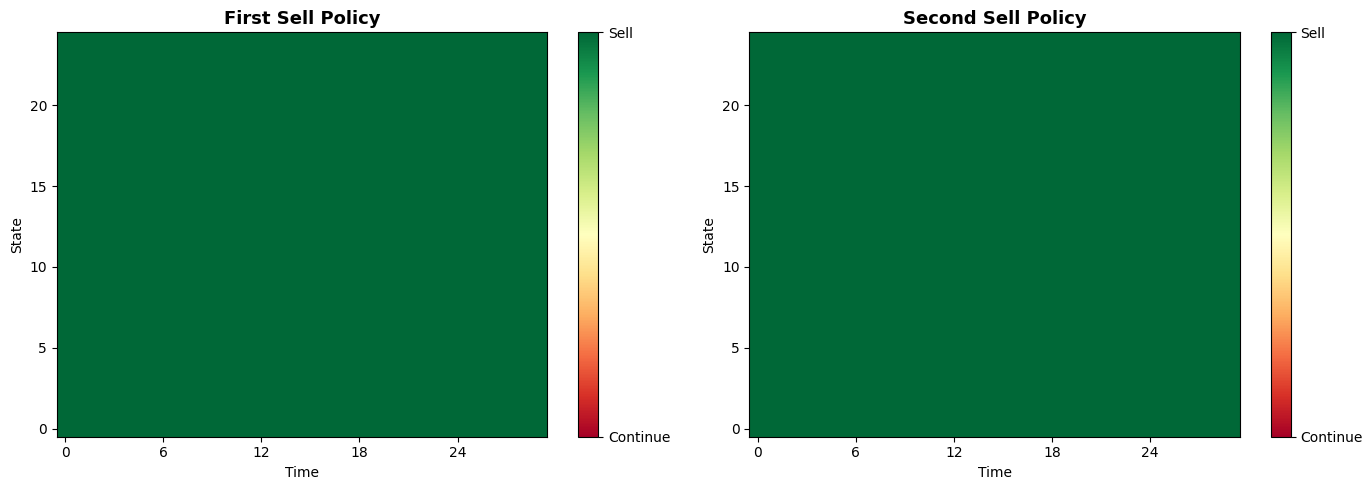


Double-Sell Policy Statistics:
 First sell rate: 100.00%
 Second sell rate: 100.00%

--- Visualizing LSM-Tabular Critic ---


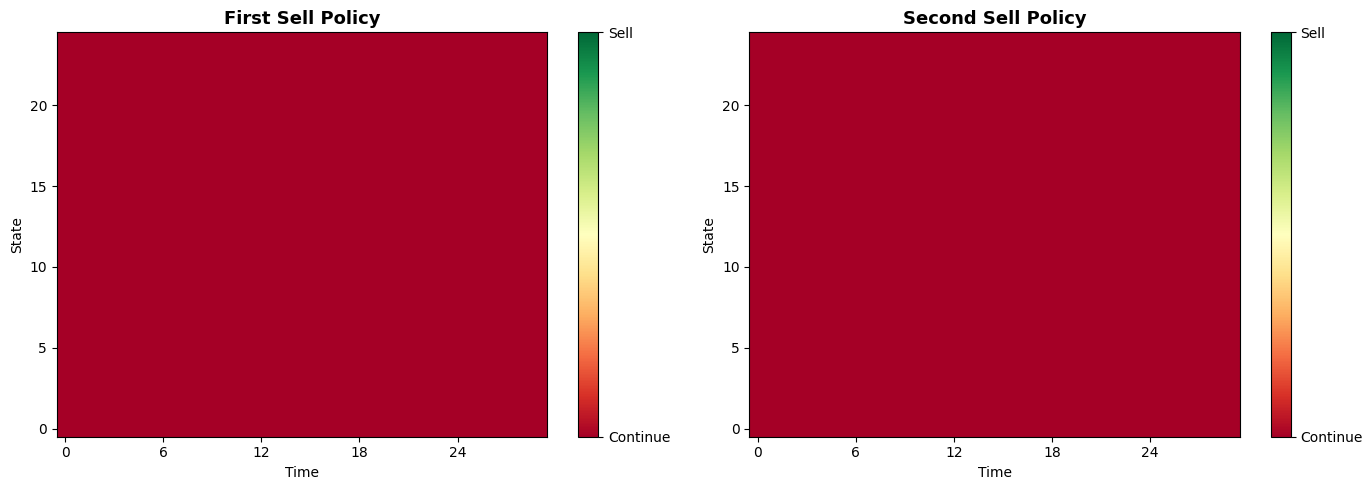


Double-Sell Policy Statistics:
 First sell rate: 0.00%
 Second sell rate: 0.00%

--- Visualizing LSM-NN Critic ---


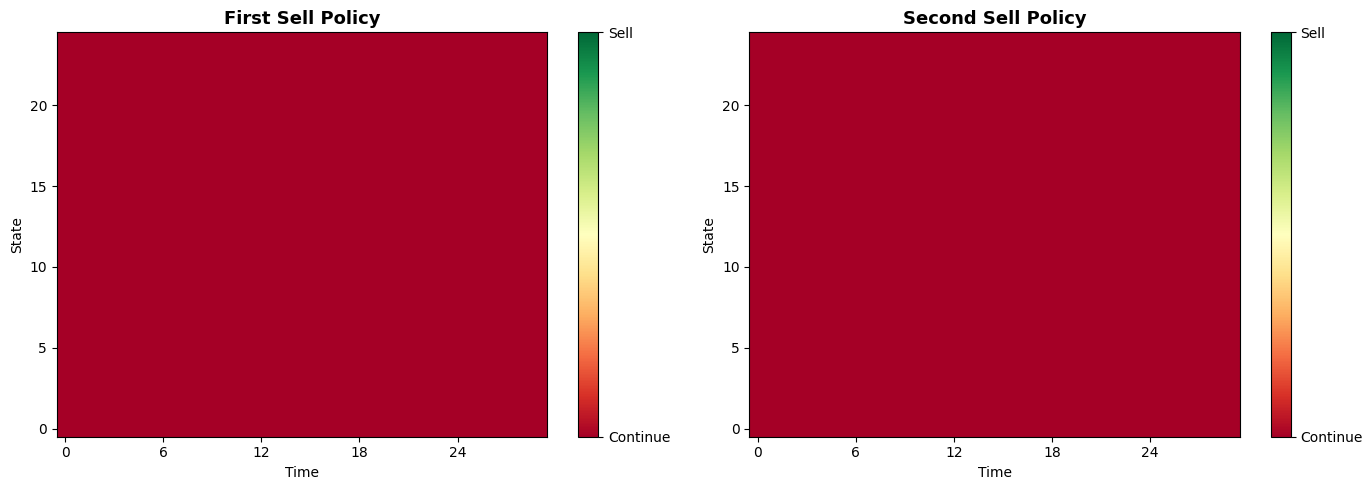


Double-Sell Policy Statistics:
 First sell rate: 0.00%
 Second sell rate: 0.00%


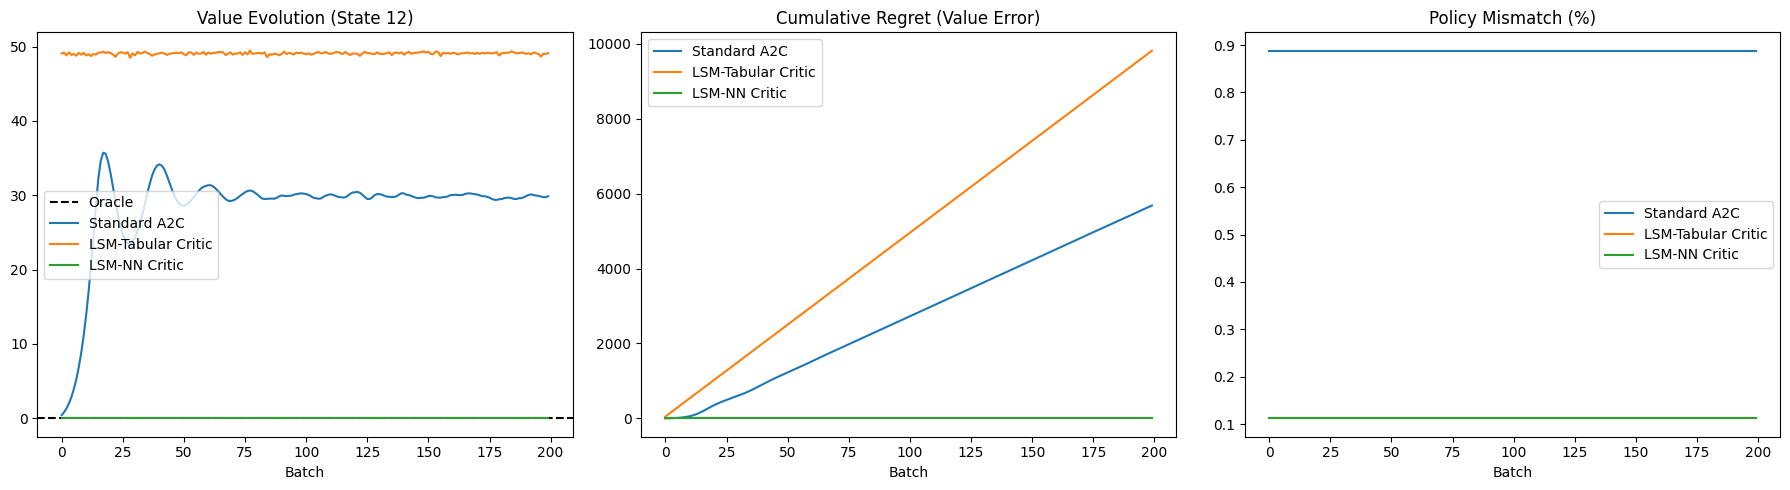

In [32]:
# ==============================================================================
# CHANGED: Main Comparative Pipeline
# ==============================================================================

def run_experiment():
    # Setup
    env = DoubleSellEnv(n_states=25, max_time=30, sell_cost=0.5, transition_model='brownian', transition_params={'mu': 15, 'sigma': 10})

    # 0. Optimal Solution for Benchmarking
    V_opt, Policy_opt = env.solve_optimal_policy(verbose=False)
    mid_state = env.n_states // 2
    
    # Initialize Agents
    agents = {
        "Standard A2C": Standard_A2C_Agent(env),
        "LSM-Tabular Critic": LSM_Critic_Agent(env, LSMDoubleSell_Adapted(env)),
        "LSM-NN Critic": LSM_Critic_Agent(env, LSM_NN_Adapted(env, epochs_per_step=10))
    }
    
    n_episodes = 200 # Number of batches
    batch_size = 256
    
    print(f"Starting Training ({n_episodes} batches of {batch_size} paths)...")
    
    # Shared Path Generator
    def get_batch():
        rng = np.random.default_rng()
        paths = np.zeros((batch_size, env.max_time + 1), dtype=int)
        paths[:, 0] = rng.integers(0, env.n_states, size=batch_size)
        if env.P is not None:
            for t in range(env.max_time):
                for i in range(batch_size):
                    paths[i, t + 1] = rng.choice(env.n_states, p=env.P[paths[i, t]])
        return paths

    # Training Loop
    for name, agent in agents.items():
        print(f"Training {name}...")
        for _ in tqdm(range(n_episodes)):
            # 1. Generate Batch (Shared logic)
            paths = get_batch()
            
            # 2. Update Agent
            agent.update(paths)
            
            # 3. Calculate Metrics
            # A. Value Evolution (at t=0, state=mid, stops=2)
            if name == "Standard A2C":
                agent.critic.eval()
                with torch.no_grad():
                    # Input: s_mid, t_max (time left), stops=2
                    v_est = agent.critic(
                        torch.tensor([mid_state]), 
                        torch.tensor([env.max_time]), 
                        torch.tensor([2])
                    ).item()
                agent.critic.train()
            else:
                # LSM agents store V table in their critic
                # Critic.get_value_estimate() returns [S, Elapsed, Stops]
                
                # --- FIX: REMOVED EXTRA .critic ACCESS ---
                V_tbl = agent.critic.get_value_estimate()
                v_est = V_tbl[mid_state, 0, 2]
                
            agent.history['value_evolution'].append(v_est)
            
            # B. Cumulative Regret (Value Error Accumulation)
            val_error = abs(V_opt[mid_state, 0, 2] - v_est)
            curr_cum = agent.history['cumulative_regret'][-1] if agent.history['cumulative_regret'] else 0
            agent.history['cumulative_regret'].append(curr_cum + val_error)
            
            # C. Policy Mismatch
            pi_agent = agent.get_policy() # [S, T+1, 3]
            pi_agent_view = pi_agent[:, :env.max_time, 1:] 
            pi_opt_view = Policy_opt[:, :env.max_time, 1:]
            mismatch = np.mean(pi_agent_view != pi_opt_view)
            agent.history['policy_mismatch'].append(mismatch)

    # --- Plotting ---
    
    # 1. Individual Results
    for name, agent in agents.items():
        print(f"\n--- Visualizing {name} ---")
        viz = visualizer(env, agent, optimal_policy=Policy_opt)
        viz.visualise_policy()
        
    # 2. Combined Metrics
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    
    # Value Evolution
    axs[0].set_title(f"Value Evolution (State {mid_state})")
    axs[0].axhline(y=V_opt[mid_state, 0, 2], color='k', linestyle='--', label='Oracle')
    for name, agent in agents.items():
        axs[0].plot(agent.history['value_evolution'], label=name)
    axs[0].legend()
    axs[0].set_xlabel("Batch")
    
    # Cumulative Regret
    axs[1].set_title("Cumulative Regret (Value Error)")
    for name, agent in agents.items():
        axs[1].plot(agent.history['cumulative_regret'], label=name)
    axs[1].legend()
    axs[1].set_xlabel("Batch")
    
    # Policy Mismatch
    axs[2].set_title("Policy Mismatch (%)")
    for name, agent in agents.items():
        axs[2].plot(agent.history['policy_mismatch'], label=name)
    axs[2].legend()
    axs[2].set_xlabel("Batch")
    
    plt.tight_layout()
    plt.show()
    return agents


agents_list = run_experiment()

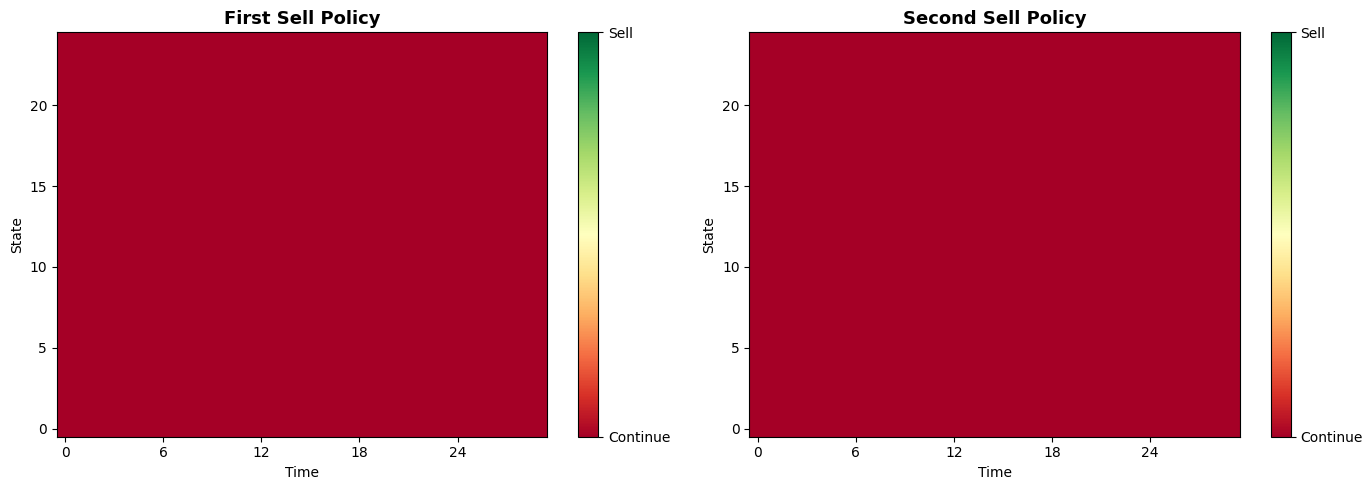


Double-Sell Policy Statistics:
 First sell rate: 0.00%
 Second sell rate: 0.00%


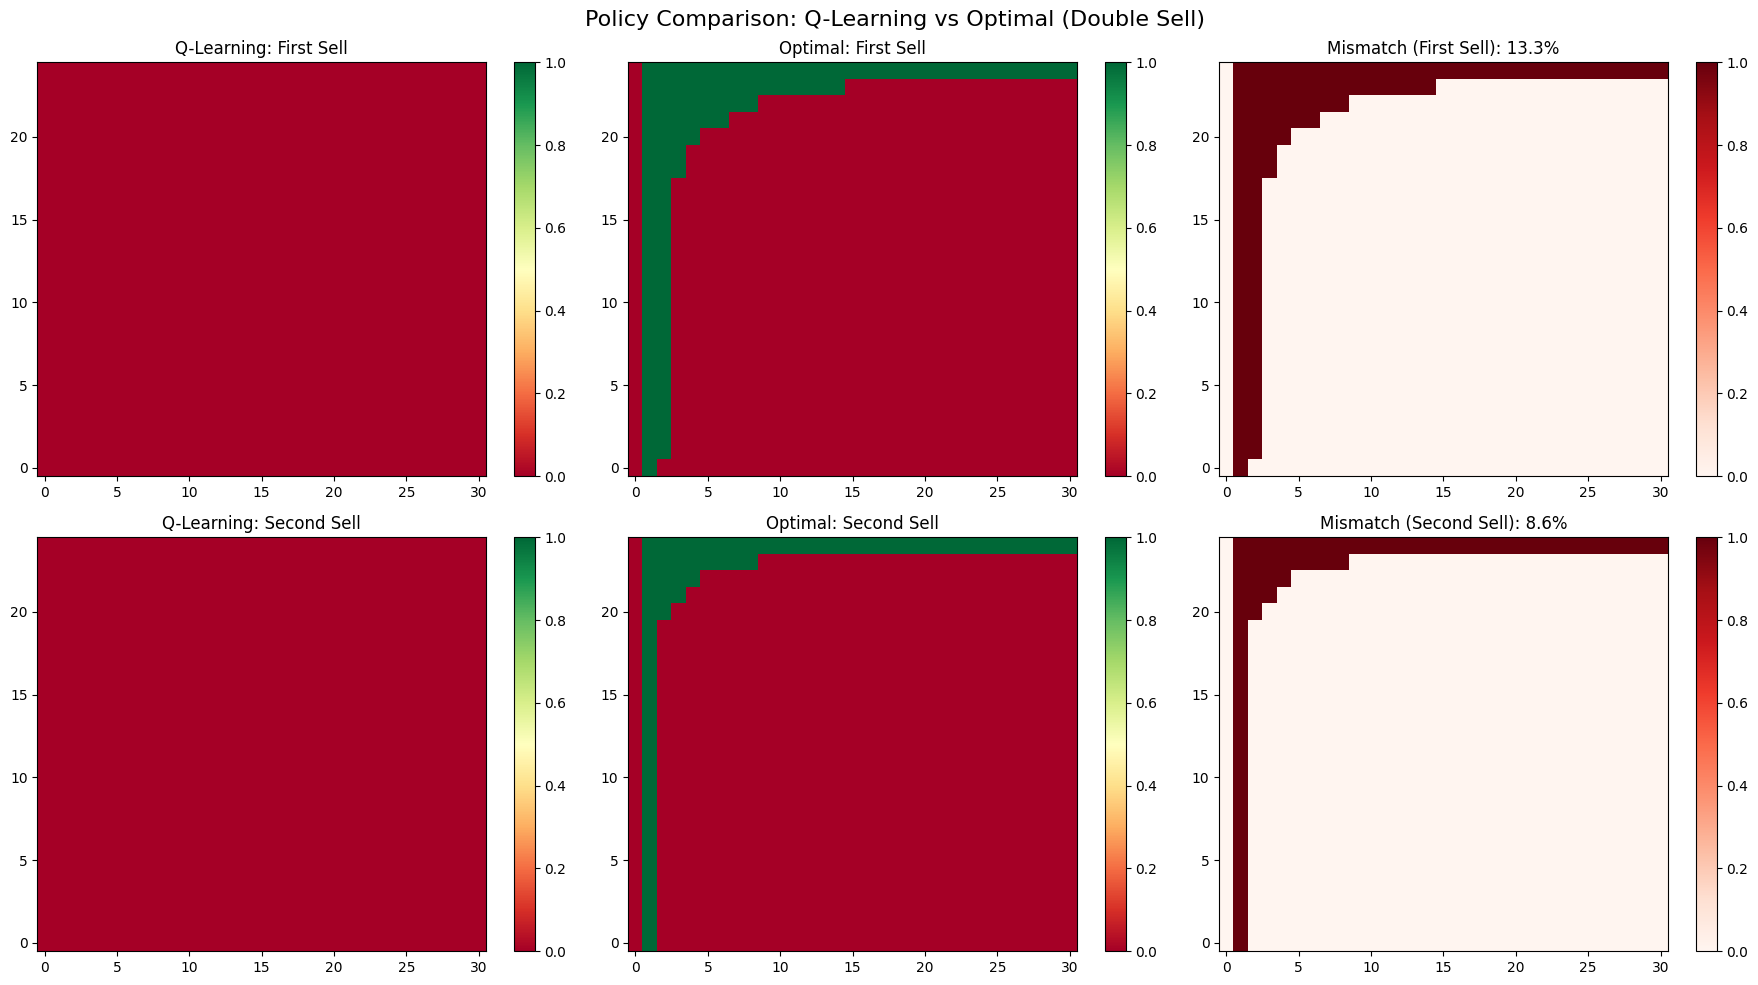


Policy Agreement Statistics (Double Sell)
 First sell agreement: 86.71%
 Second sell agreement: 91.35%
 Overall agreement: 89.03%


In [33]:
env = DoubleSellEnv(n_states=25, max_time=30, sell_cost=0.5, transition_model='brownian', transition_params={'mu': 15, 'sigma': 10})
viz = visualizer(env, agents_list["LSM-NN Critic"])

# 1. Visualize the policy learned by LSM
viz.visualise_policy()

# 2. Compare LSM policy against the DP Oracle
# This confirms if the regression successfully converged to the optimal solution.
viz.compare_with_optimal()

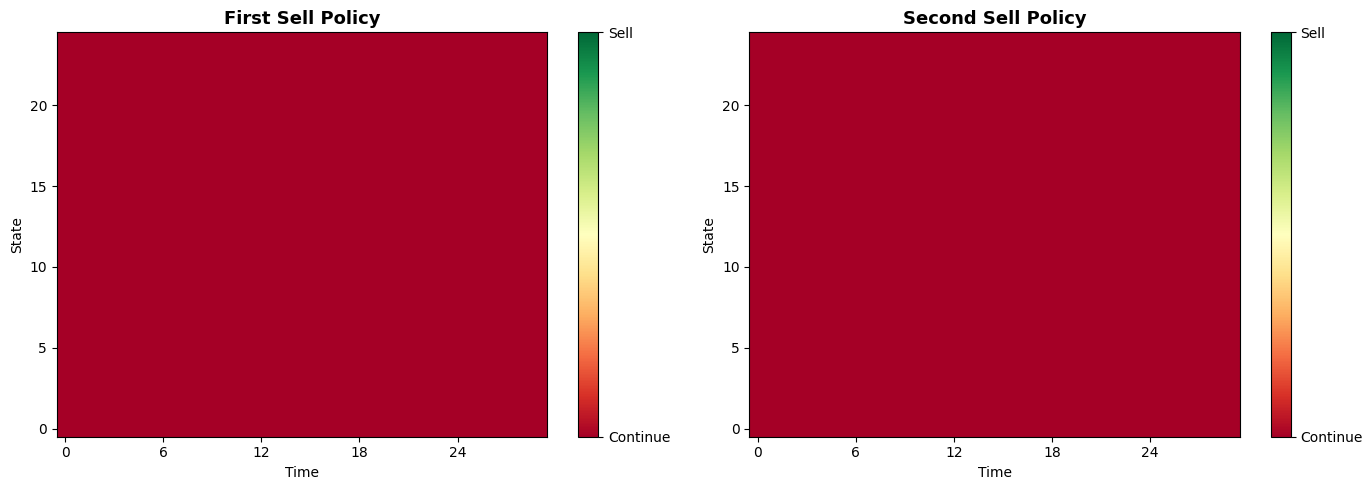


Double-Sell Policy Statistics:
 First sell rate: 0.00%
 Second sell rate: 0.00%


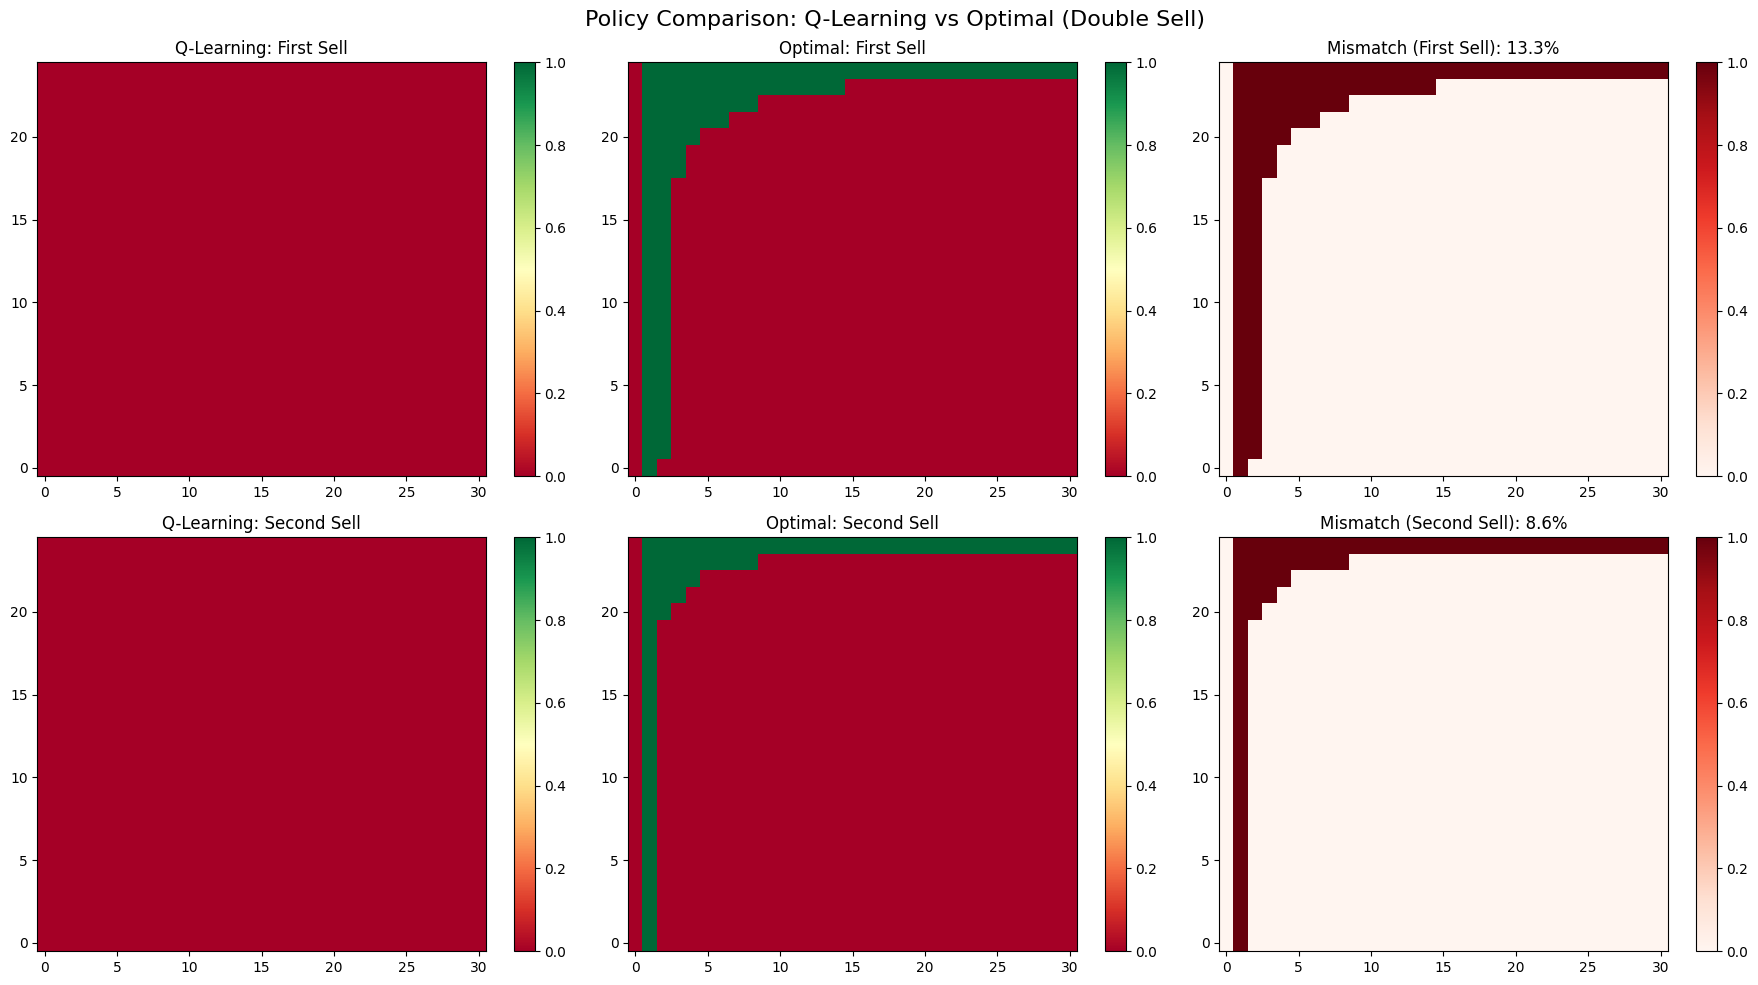


Policy Agreement Statistics (Double Sell)
 First sell agreement: 86.71%
 Second sell agreement: 91.35%
 Overall agreement: 89.03%


In [34]:
viz = visualizer(env, agents_list["LSM-Tabular Critic"])

# 1. Visualize the policy learned by LSM
viz.visualise_policy()

# 2. Compare LSM policy against the DP Oracle
# This confirms if the regression successfully converged to the optimal solution.
viz.compare_with_optimal()

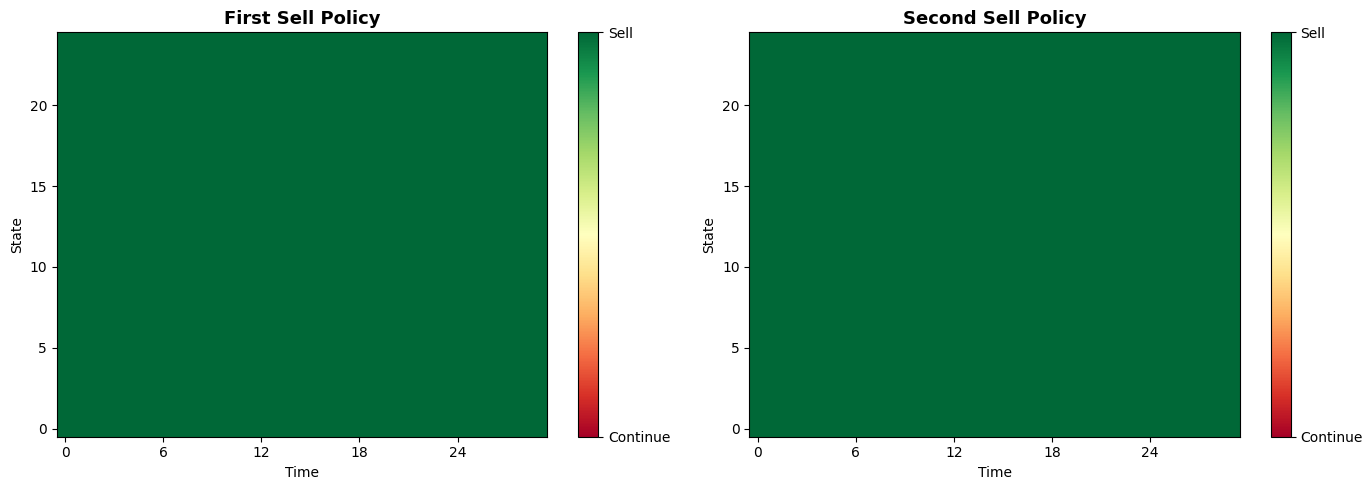


Double-Sell Policy Statistics:
 First sell rate: 100.00%
 Second sell rate: 100.00%


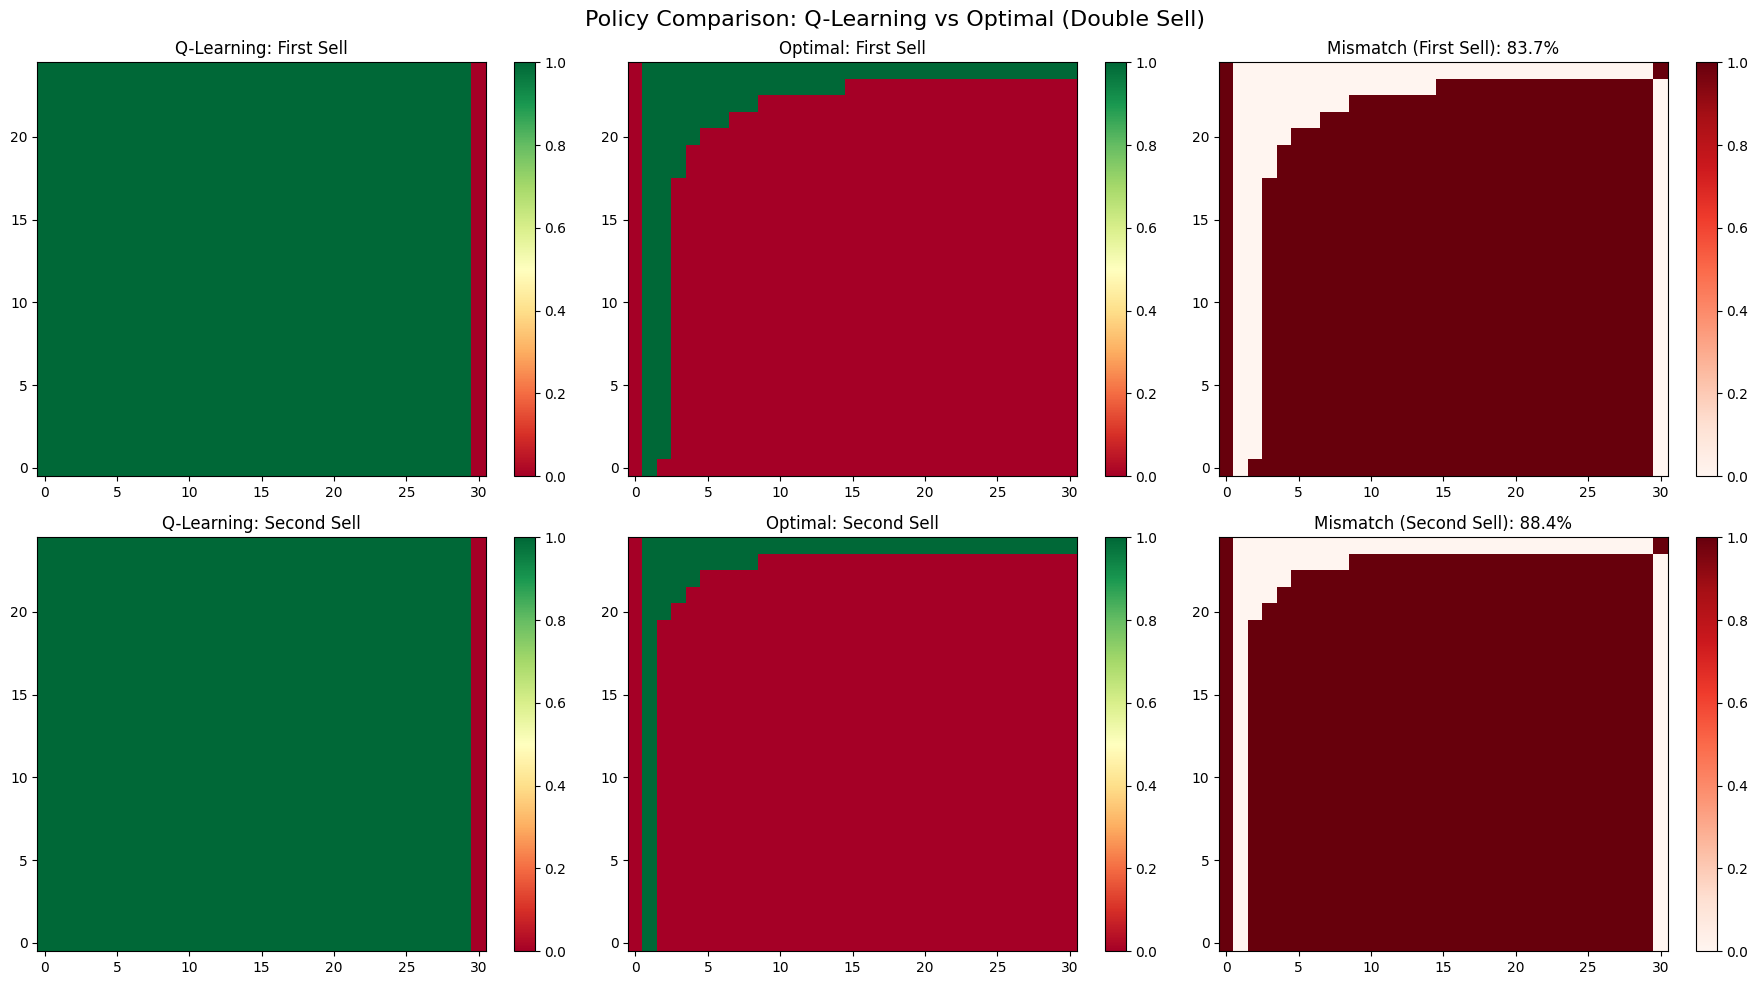


Policy Agreement Statistics (Double Sell)
 First sell agreement: 16.26%
 Second sell agreement: 11.61%
 Overall agreement: 13.94%


In [35]:
viz = visualizer(env, agents_list["Standard A2C"])

# 1. Visualize the policy learned by LSM
viz.visualise_policy()

# 2. Compare LSM policy against the DP Oracle
# This confirms if the regression successfully converged to the optimal solution.
viz.compare_with_optimal()